# Table for Four - Data Ingestion and Data Transformation

#### Description
For simplicity, all project-related scripts are set up within the 'festival' schema, due to its pre-established connection to the server. Within the 'model' folder in 'festival', we created a stand alone folder with our an abbreviation of our team name, 't4f', to avoid conflicts. Within our project folder, three separate folders are created dedicated for different purpose:
- 't4f_staging': includes all staging files 
- 't4f_star_schema': includes all dimensions and 't4f_schema.yml' to illustrate relationships

#### t4f_staging

path: festival/models/t4f_staging

All staging models are housed here to ingest all original dataset with some cleaning steps, such as enforcing consistent case in 'patient'

In [ ]:
# -- stg_providers.sql

select
    provider_id,
    provider_name,
    specialty,
    npi_number,
    department_id,
    hire_date::date as hire_date
from {{source('festival', 'providers')}}

# -- stg_procedure_codes.sql

select 
    procedure_code,
    procedure_description,
    base_cost
from {{source('festival', 'procedure_codes')}}

# -- stg_patients.sql

select 
    distinct -- remove the duplicate rows
    patient_id,
    insurance_id,
    first_name,
    last_name,
    date_of_birth,
    CASE 
        when gender ilike '%F%' then 'F'
        else 'M'
        END AS gender,
    zip_code,
    primary_language,
    phone,
    email,
    registration_date::date as registration_date
from {{source('festival', 'patients')}}

# -- stg_insurance_plans.sql

select 
    insurance_id,
    payer_name,
    plan_type,
    avg_copay,
    annual_deductible
from {{source('festival', 'insurance_plans')}}

# -- stg_facilities.sql

select 
    facility_id,
    facility_name,
    city,
    state, 
    licensed_beds
from {{source('festival', 'facilities')}}

# -- stag_encounters.sql

select 
    encounter_id,
    patient_id,
    provider_id,
    facility_id,
    department_id, 
    diagnosis_code,
    procedure_code,
    encounter_type,
    admit_date::date,
    discharge_date::date,
    encounter_status,
    total_charge,
    insurance_paid,
    patient_paid
from {{source('festival', 'encounters')}}

# -- stg_diagnosis_codes.sql

select 
    diagnosis_code,
    diagnosis_description,
    diagnosis_category,
    chronic_flag
from {{source('festival', 'diagnosis_codes')}}

-- stg_departments.sql

select 
    department_id,
    facility_id,
    department_name,
    cost_center
from {{source('festival', 'departments')}}

#-- stg_appointments.sql

select 
    appointment_id,
    patient_id,
    provider_id,
    facility_id,
    encounter_id,
    diagnosis_code,
    scheduled_date::date as scheduled_date,
    scheduled_time,
    LOWER(appointment_type) as appointment_type,
    LOWER(appointment_status) as appointment_status
from {{source('festival', 'appointments')}}


-- t4f_sources.yml

version: 2

sources:
  - name: festival
    description: "Configuration model establishing source of truth"
    schema: yl42556_t4f_schema
    tables:
      - name: appointments
      - name: encounters
      - name: patients
      - name: providers
      - name: facilities
      - name: departments
      - name: diagnosis_codes
      - name: procedure_codes
      - name: insurance_plans

#### t4f_star_schema
path: festival/models/t4f_star_schema

All dimensions and star schema yml files are housed here to establish relationship

In [ ]:
# -- fact_appointment.sql
{{ config(materialized="table") }}
    
with a as (select * from {{ref('stg_appointments')}}),
    pt as (select * from {{ref('stg_patients')}}),
    e as (select * from {{ref('stg_encounters')}})
    
select 
    a.appointment_id,
    a.encounter_id as encounter_id, -- null if never occured
    (a.encounter_id is not null) as encounter_occurred, -- for quick look up

    -- key to dimensions
    a.patient_id as patient_key,
    a.provider_id as provider_key,
    a.facility_id as facility_key,
    a.diagnosis_code as diagnosis_key,
    e.department_id as department_key,   -- from encounter
    e.procedure_code as procedure_key,   -- from encounter
    pt.insurance_id as insurance_key,    -- from patient
    
    a.appointment_type,
    a.appointment_status,
    e.encounter_type,
    
    a.scheduled_date,
    a.scheduled_time,
    e.admit_date,
    e.discharge_date
from a
left join pt on pt.patient_id = a.patient_id
left join e on e.encounter_id = a.encounter_id


# -- dim_provider.sql
{{ config(materialized="table") }}

select 
    provider_id as provider_key,
    provider_name,
    specialty as provider_specialty,
    npi_number,
    hire_date
from {{ref('stg_providers')}}


# -- dim_procedire.sql
{{ config(materialized="table") }}

select 
    procedure_code as procedure_key,
    procedure_description,
    base_cost
from {{ref('stg_procedure_codes')}}

# -- dim_patient.sql
{{ config(materialized="table") }}

select 
    patient_id as patient_key,
    first_name,
    last_name,
    date_of_birth as dob,
    gender,
    zip_code,
    primary_language,
    email,
    registration_date
from {{ref('stg_patients')}}

# -- dim_insurance.sql
{{ config(materialized="table") }}

select 
    insurance_id as insurance_key,
    payer_name as insurer_name,
    plan_type,
    avg_copay,
    annual_deductible
from {{ref('stg_insurance_plans')}}

# -- dim_facility.sql
{{ config(materialized="table") }}

select 
    facility_id as facility_key,
    facility_name,
    city,
    state,
    licensed_beds
from {{ref('stg_facilities')}}

# -- dim_diagnosis.sql
{{ config(materialized="table") }}

select 
    diagnosis_code as diagnosis_key,
    diagnosis_description,
    diagnosis_category,
    chronic_flag
from {{ref('stg_diagnosis_codes')}}

# -- dim_department.sql
{{ config(materialized="table") }}

select 
    department_id as department_key,
    department_name,
    cost_center
from {{ref('stg_departments')}}

-- 't4f_schema.yml'

version: 2

models:
  - name: dim_department
    columns:
      - name: department_key
        data_tests: [unique, not_null]

  - name: dim_diagnosis
    columns:
      - name: diagnosis_key
        data_tests: [unique, not_null]

  - name: dim_facility
    columns:
      - name: facility_key
        data_tests: [unique, not_null]
        
  - name: dim_patient
    columns:
      - name: patient_key
        data_tests: [unique, not_null]
        
  - name: dim_procedure
    columns:
      - name: procedure_key
        data_tests: [unique, not_null]     

  - name: dim_provider
    columns:
      - name: provider_key
        data_tests: [unique, not_null]
        
  - name: dim_insurance
    columns:
      - name: insurance_key
        data_tests: [unique, not_null]
      - name: plan_type
        data_tests:
          - accepted_values:
              arguments:
                values: ['PPO','HMO','EPO','Government']

  - name: fact_appointment
    columns:
      - name: appointment_id
        data_tests: [unique, not_null]
        
      - name: encounter_id
        data_tests: [unique, not_null]
        
      - name: patient_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_patient')
                field: patient_key
                
      - name: provider_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_provider')
                field: provider_key
                
      - name: facility_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_facility')
                field: facility_key
                
      - name: diagnosis_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_diagnosis')
                field: diagnosis_key
                
      - name: department_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_department')
                field: department_key
                
      - name: procedure_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_procedure')
                field: procedure_key
                
      - name: insurance_key
        data_tests:
          - relationships:
              arguments:
                to: ref('dim_insurance')
                field: insurance_key
                
      - name: appointment_type
        data_tests:
          - accepted_values:
              arguments:
                values: ['Lab Work', 'Follow-up', 'Annual Physical','Consultation','Imaging', 'Pre-op', 'Post-discharge Check']
                
      - name: appointment_status
        data_tests:
          - accepted_values:
              arguments:
                values: ['Completed', 'No-Show', 'Cancelled']

#### Screenshots of all staging return

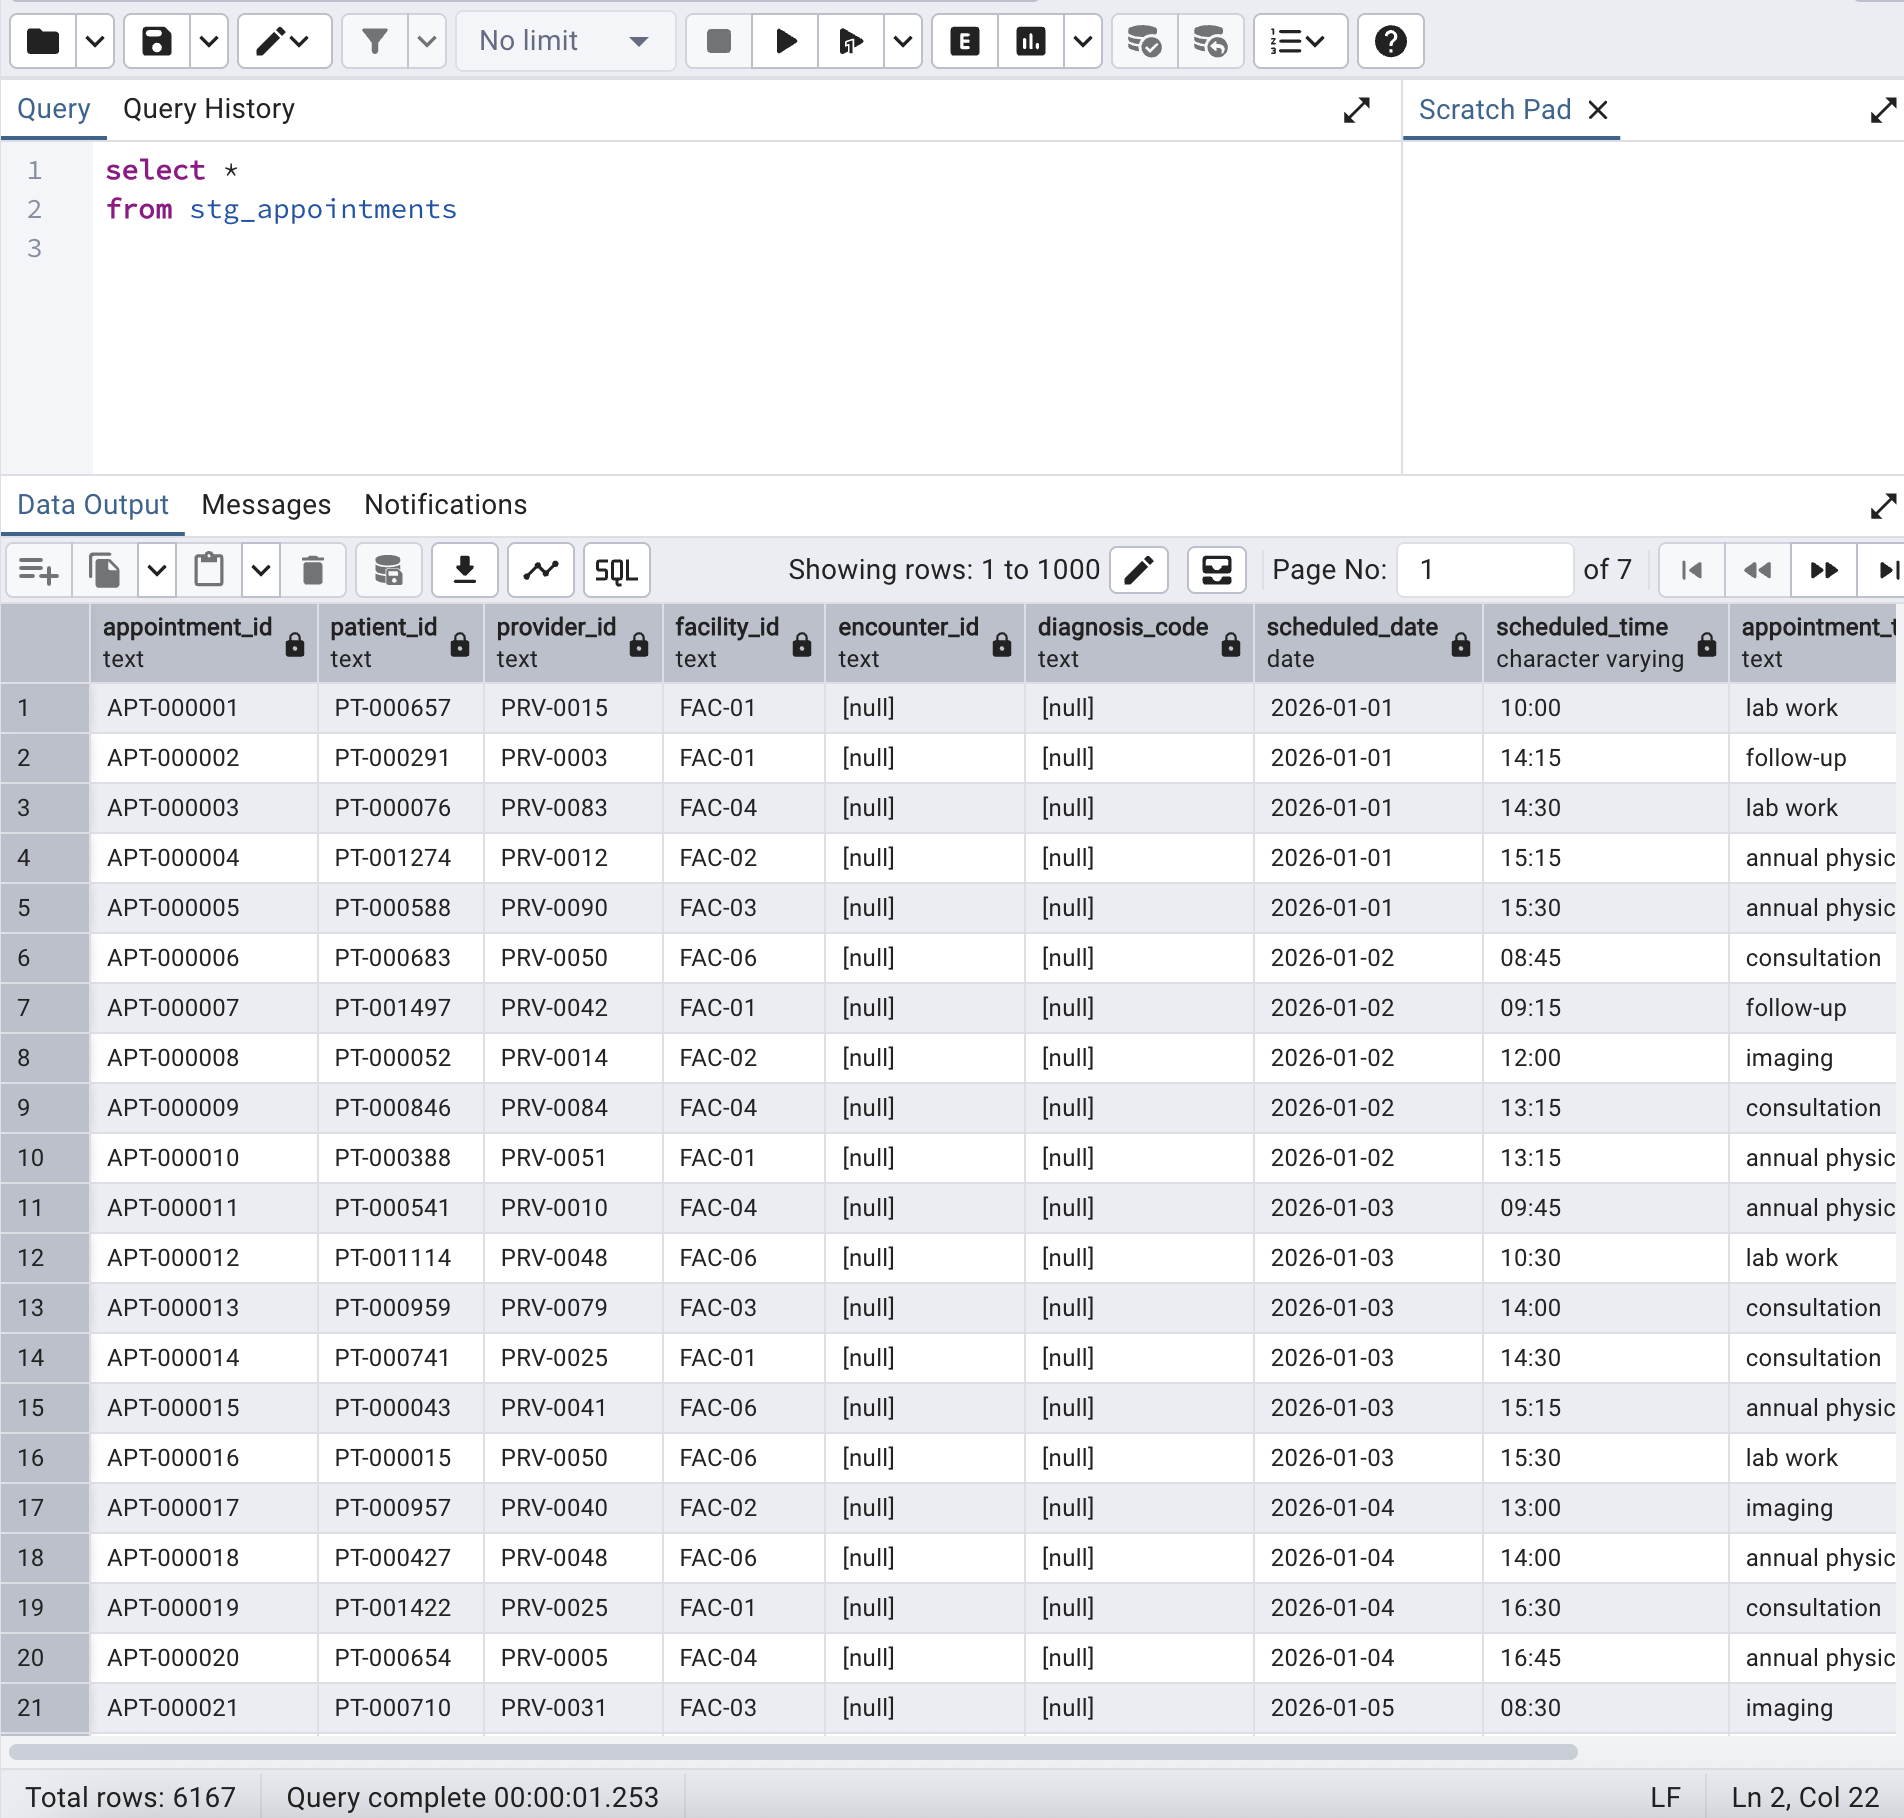

'stg_appointments': returned 6167 rows

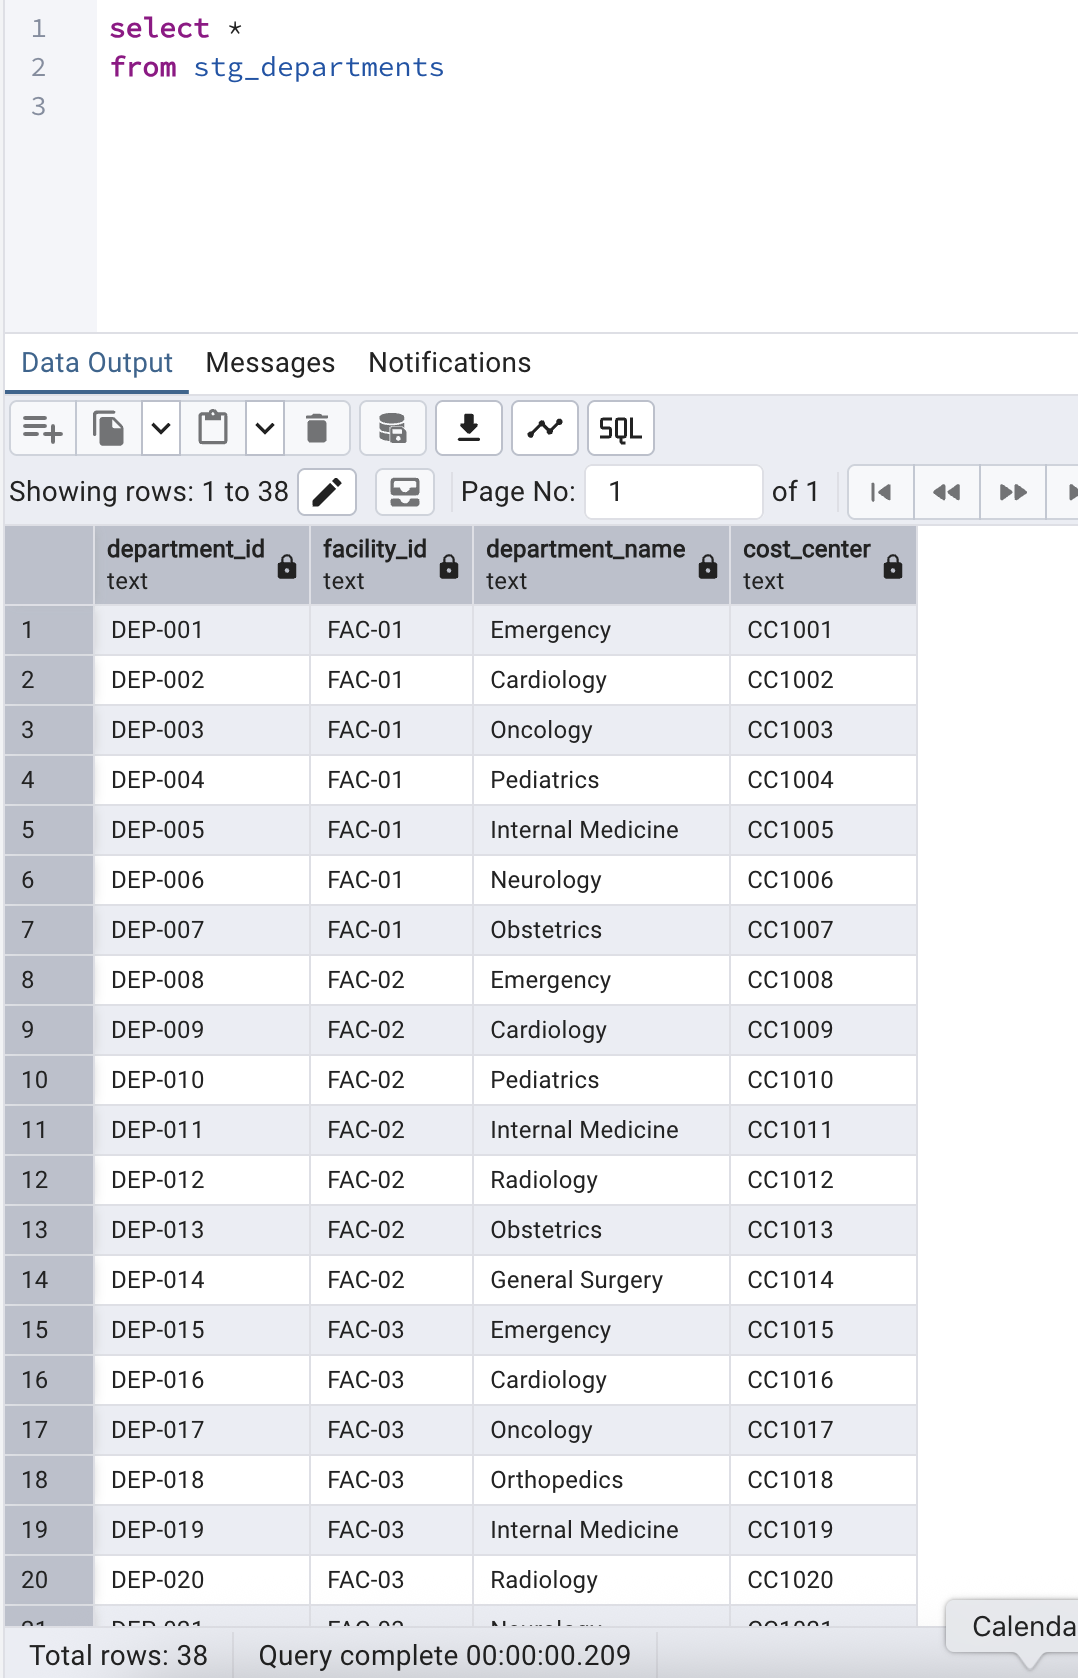

'stag_departments': returned 38 rows

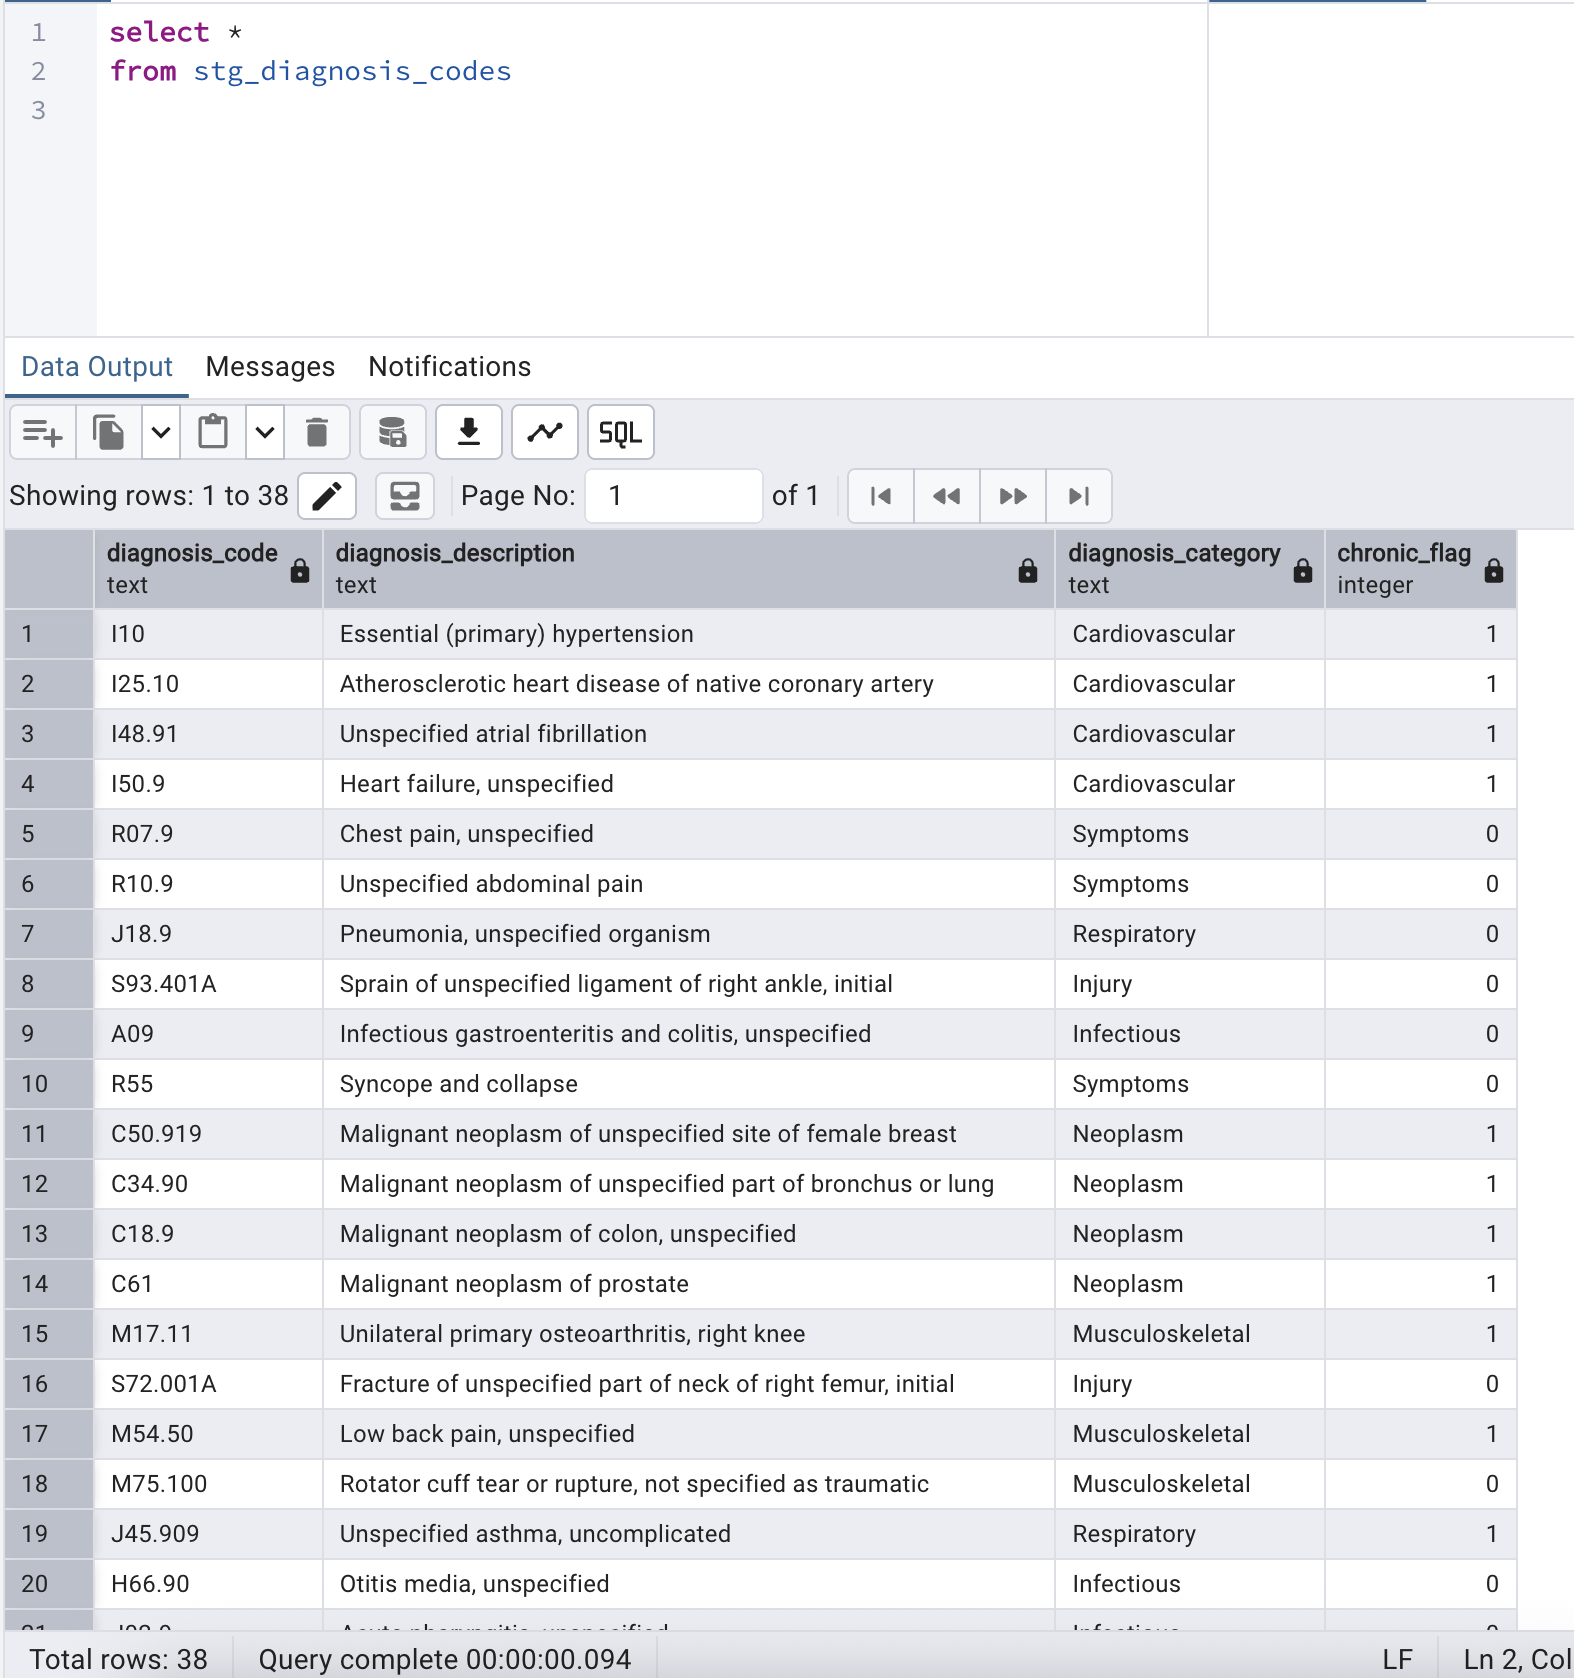

'stg_diagnosis_codes': returned 38 rows

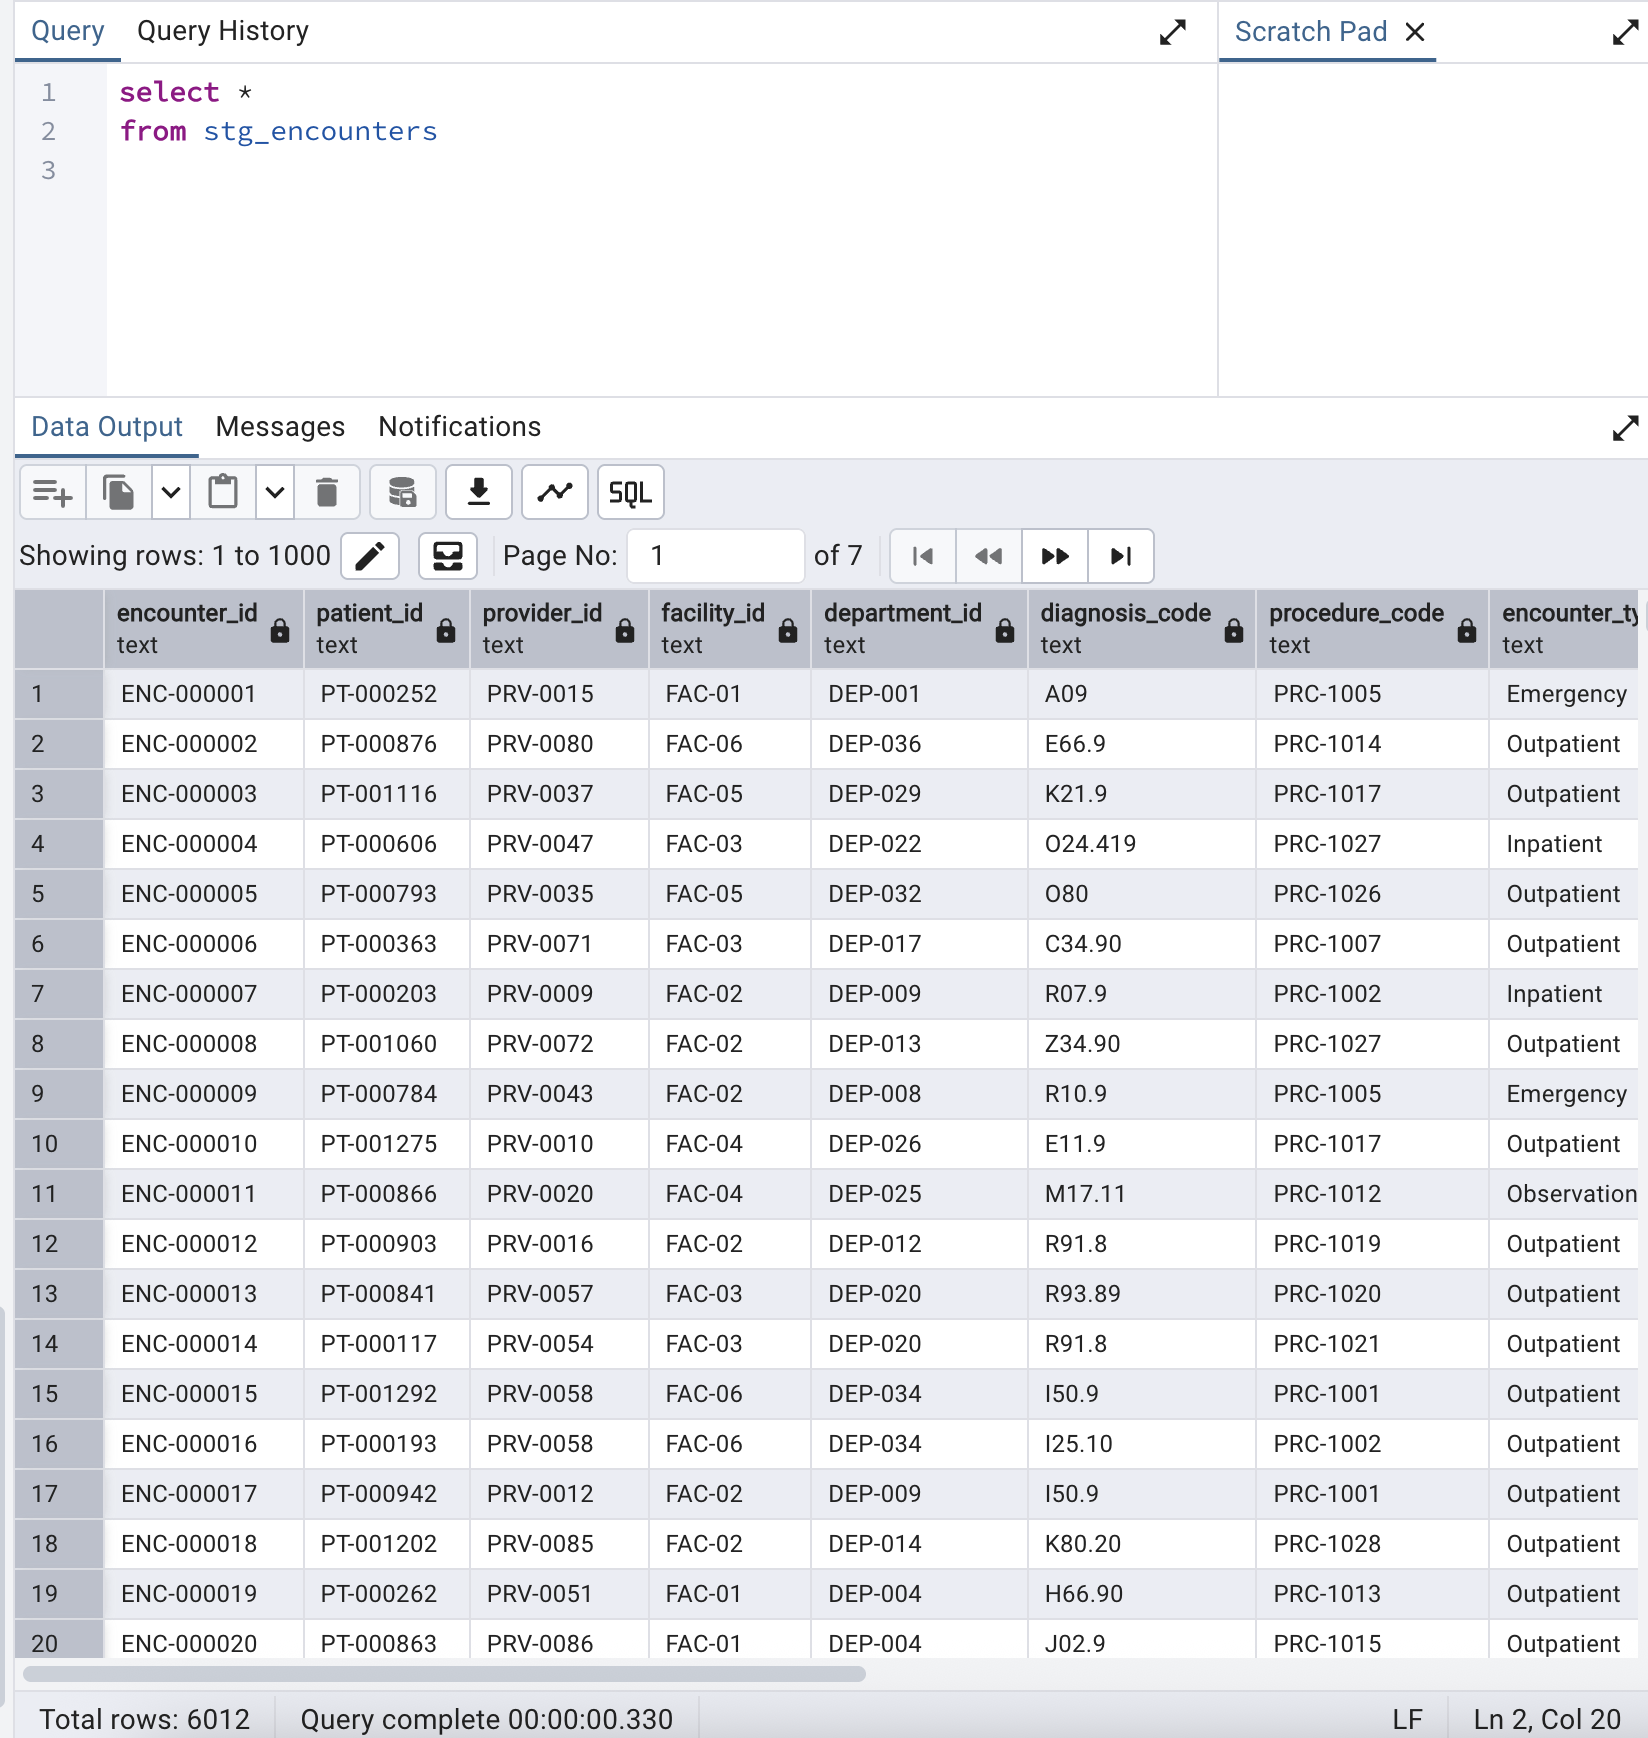

'stg_encounters': returbed 6012 rows

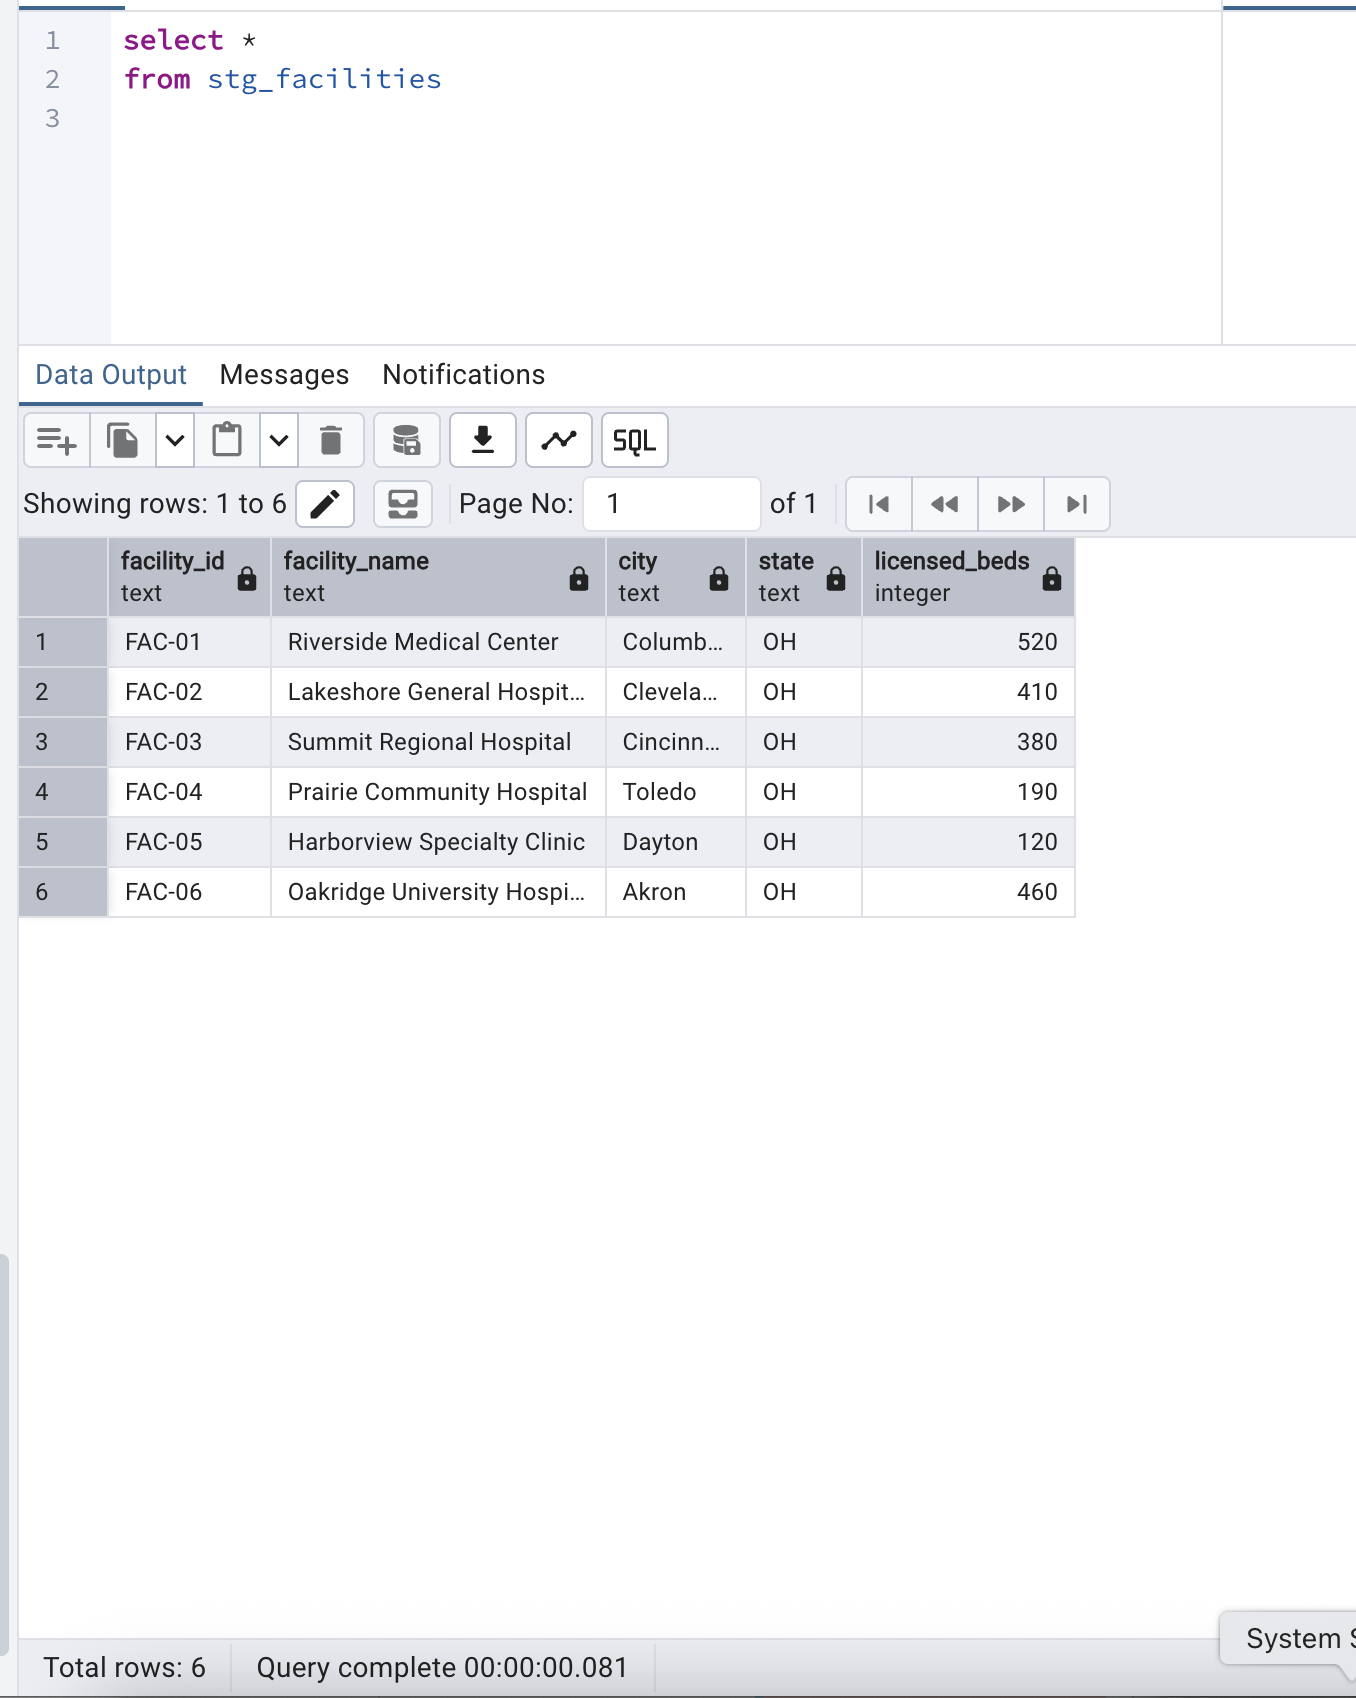

'stg_facilities': returned 6 rows

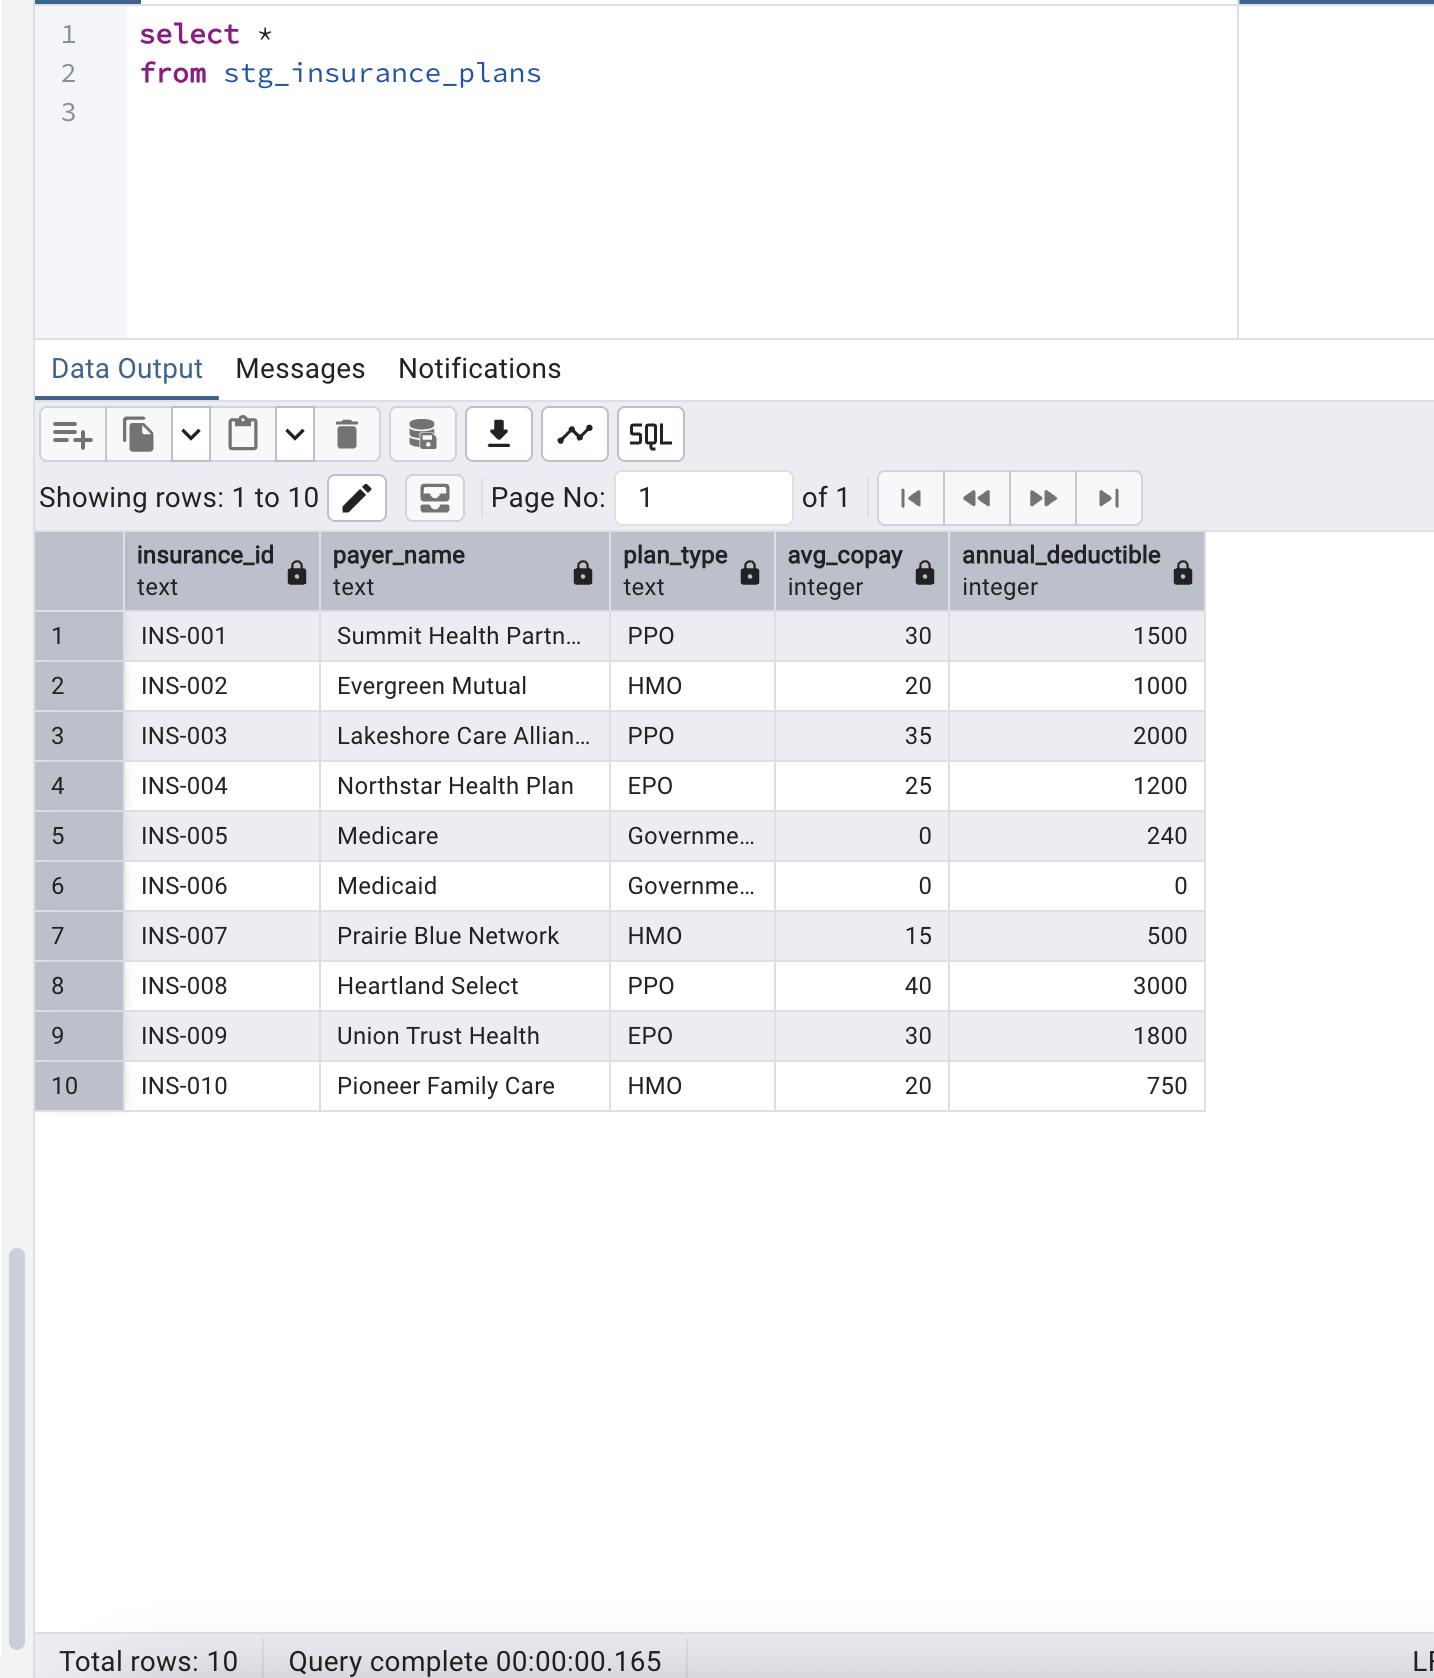

'stg_insurance_plans': returned 10 rows

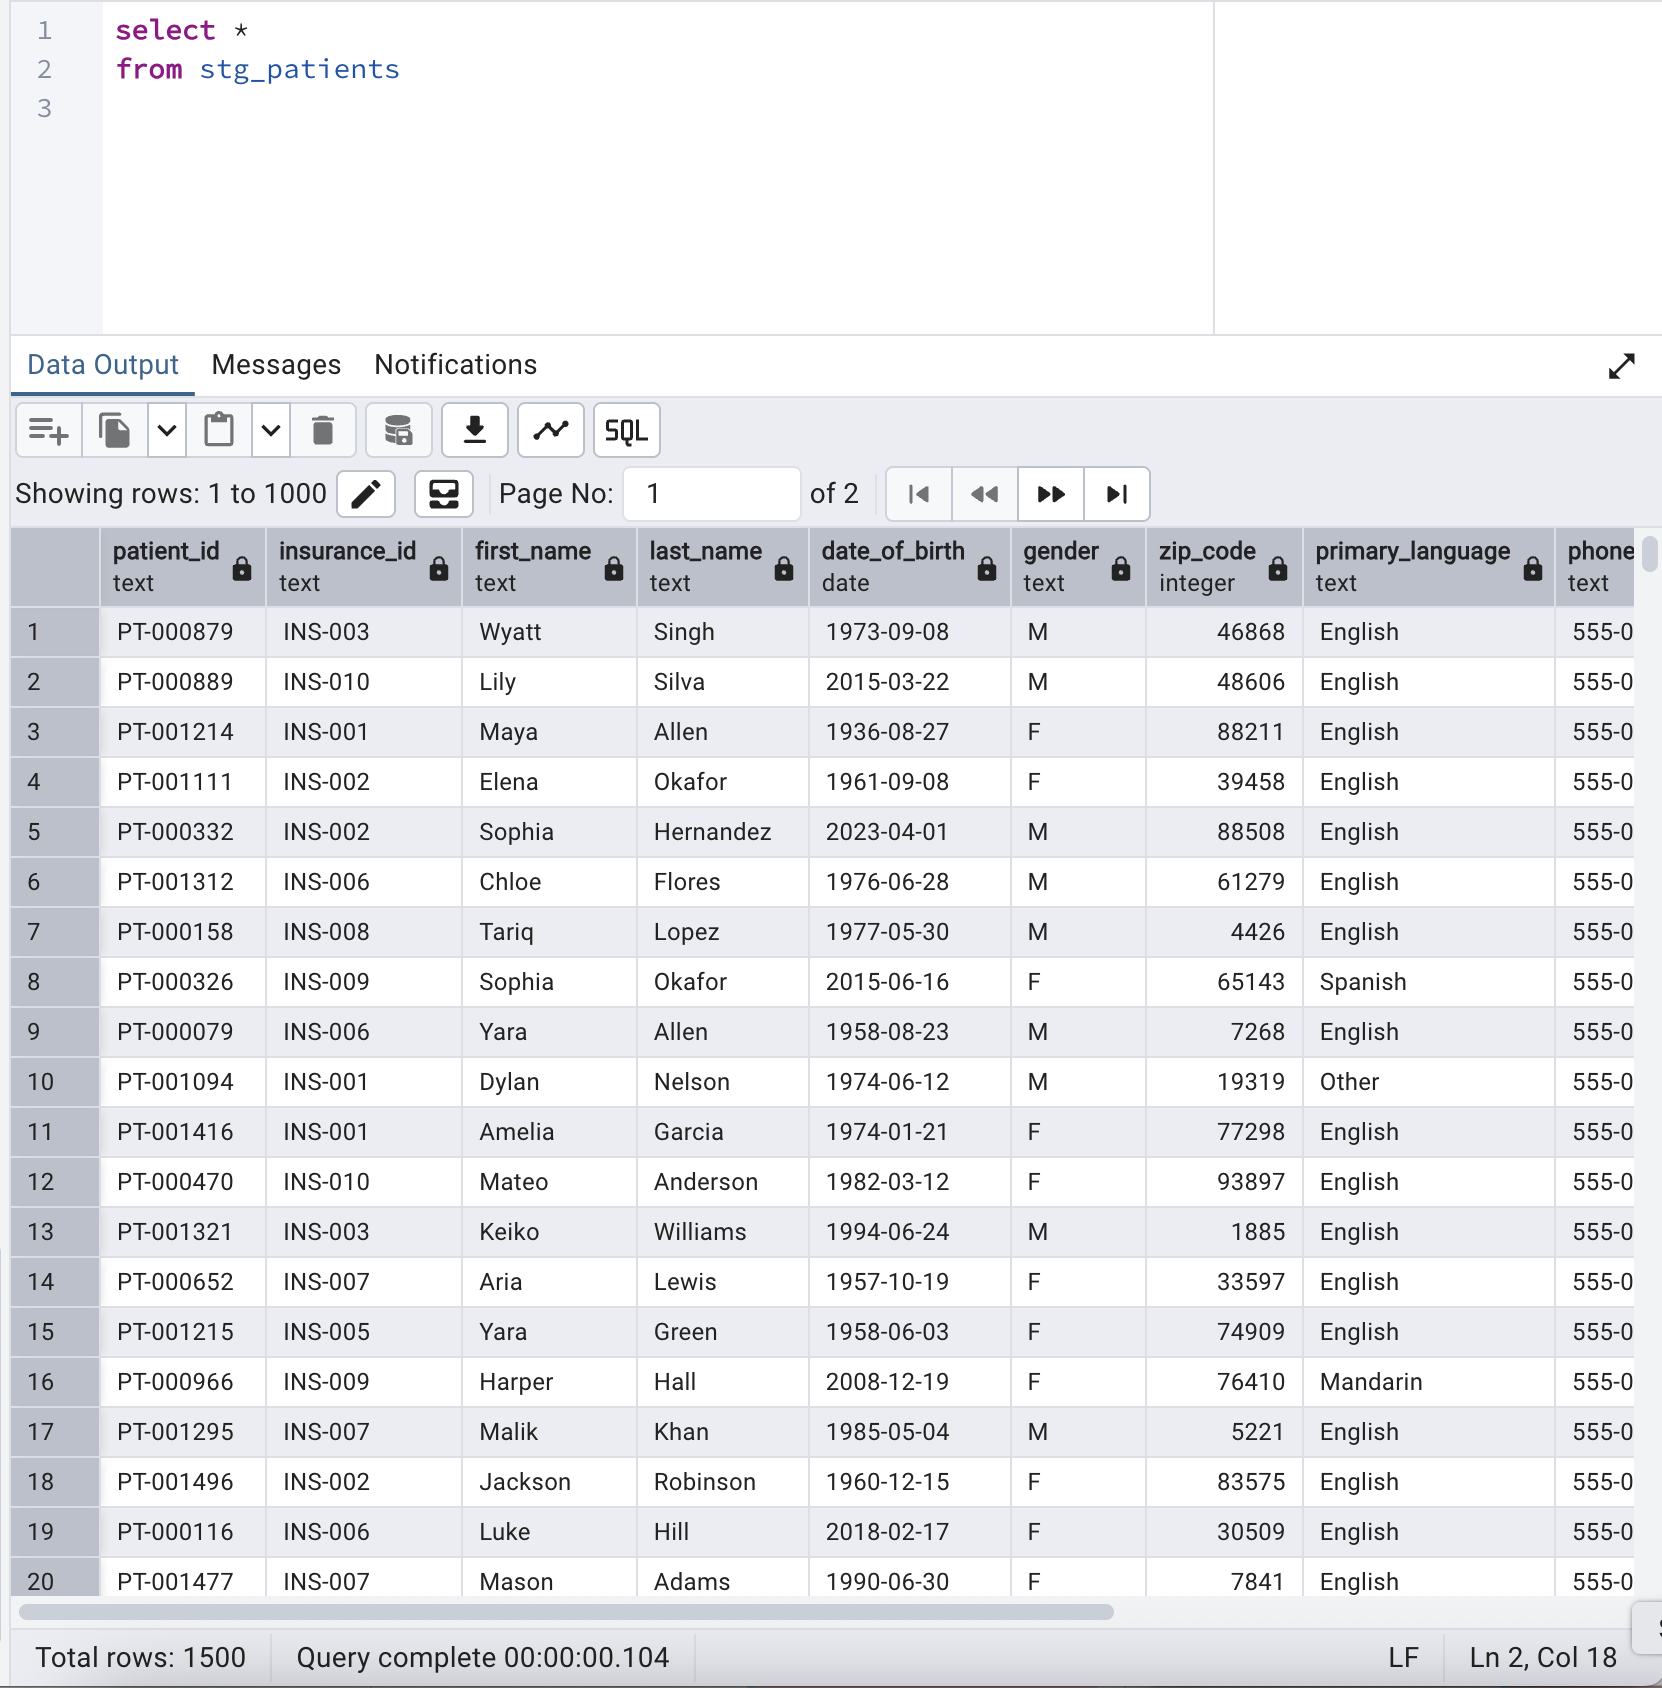

'stg_patients': returned 1500 rows

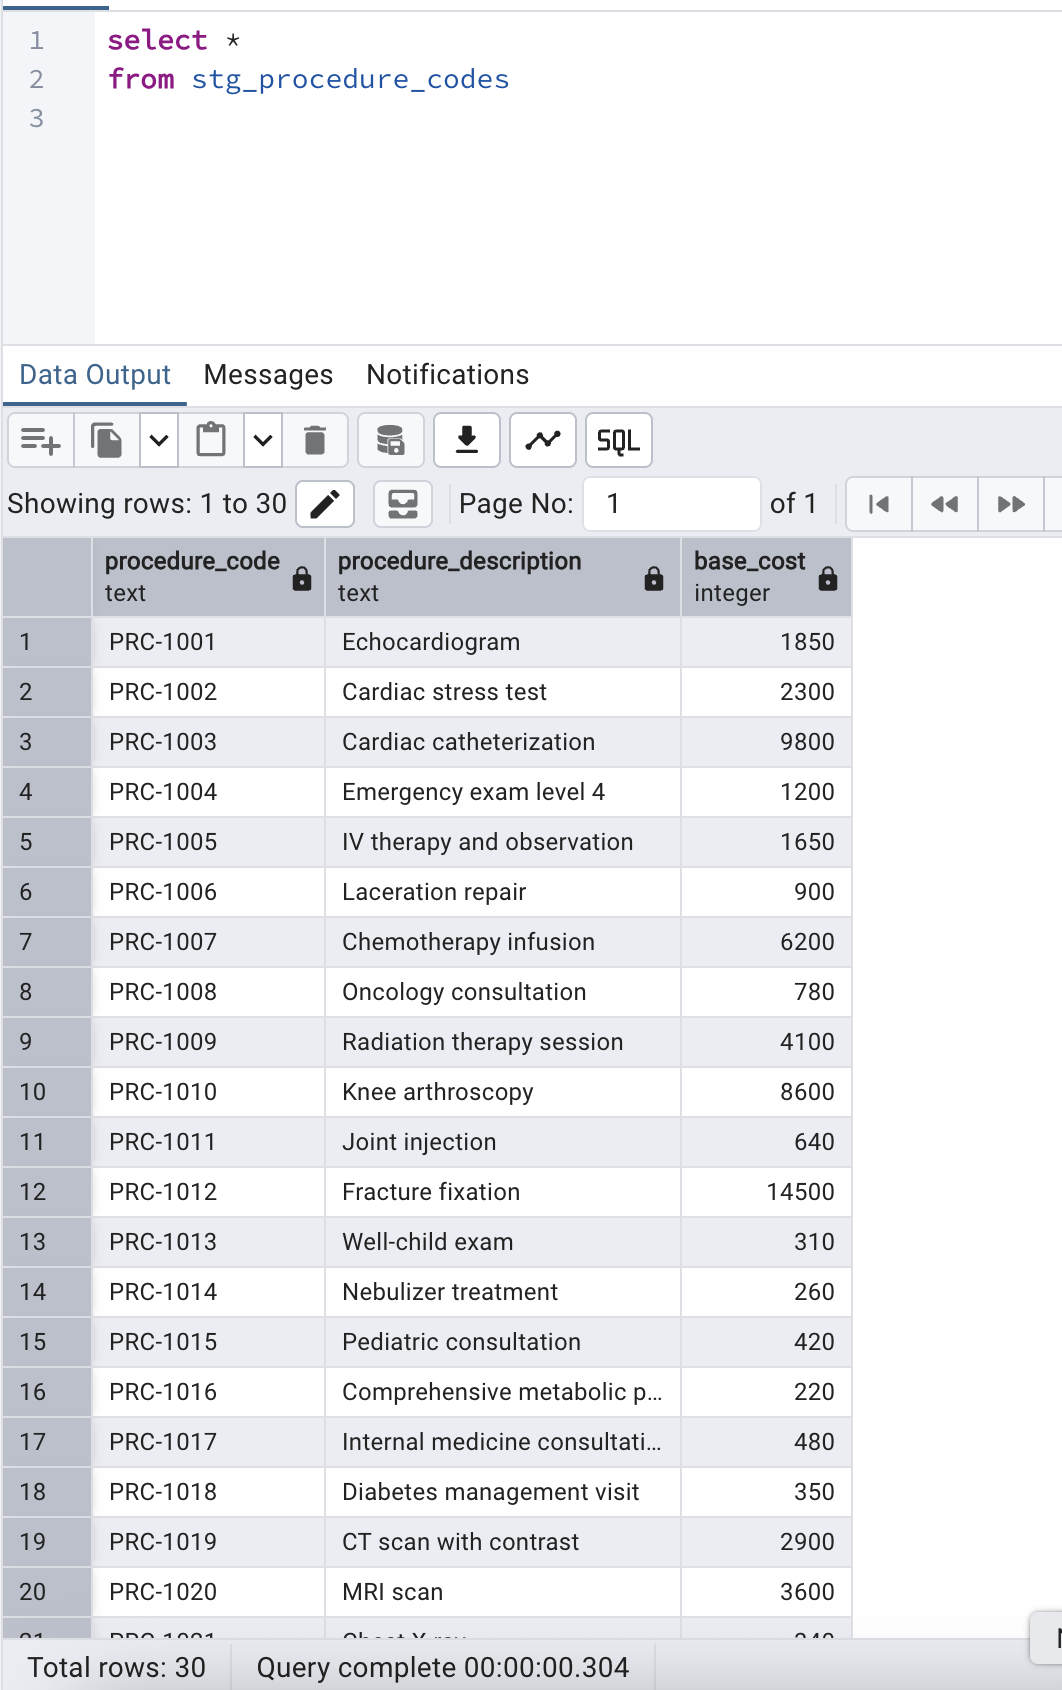

'stg_procedure_codes': returned 30 rows

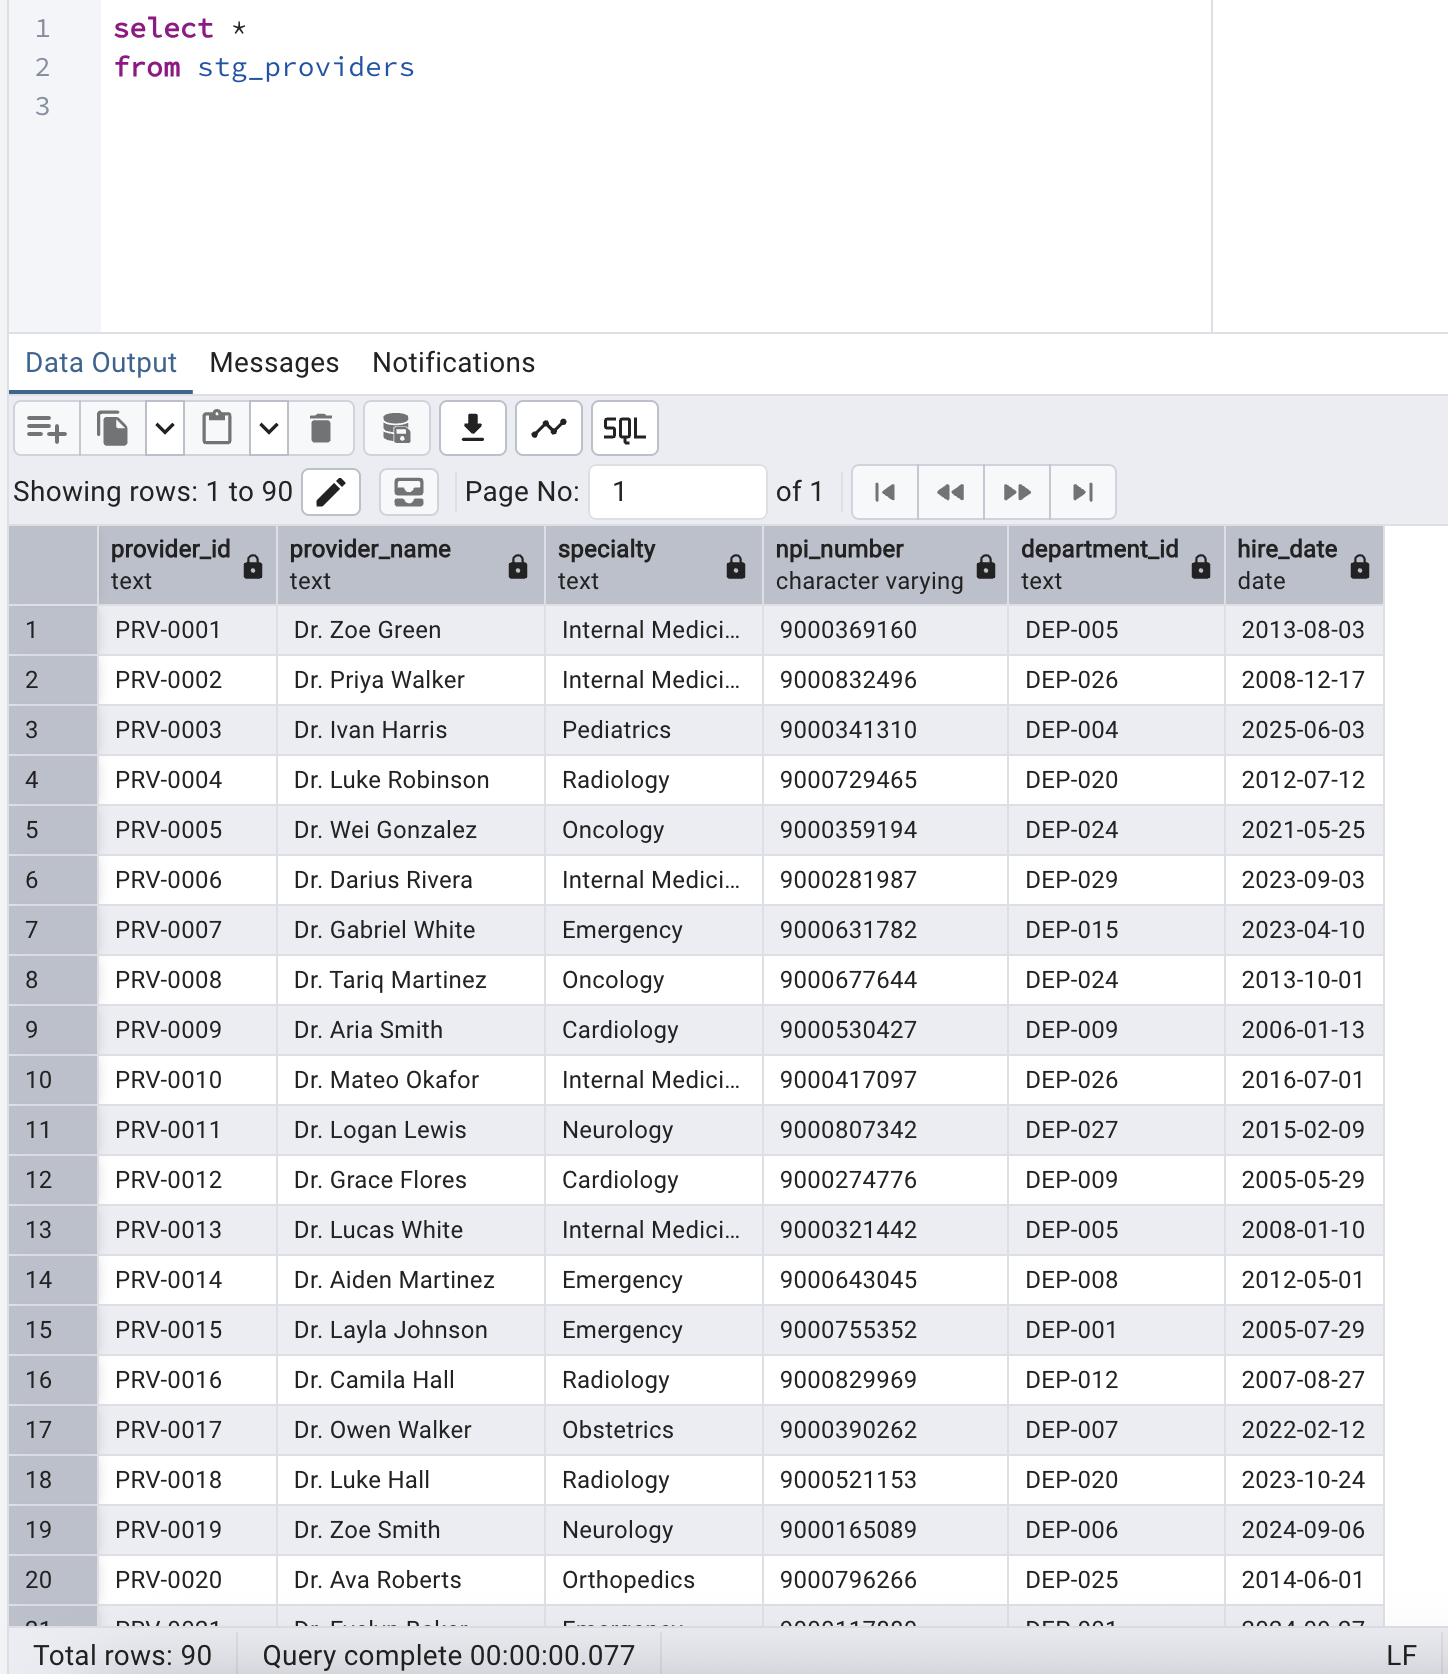

'stg_providers': returned 90 rows